In [2]:
import os
import math
from matplotlib import pyplot as plt
from matplotlib import patches
import numpy as np
import pandas as pd
import seaborn as sns
import pynwb
import h5py

from sklearn.decomposition import PCA
from sklearn.cross_decomposition import CCA
from sklearn.metrics import r2_score

import jax
import jax.numpy as jnp
import optax

from distinctipy import distinctipy

In [3]:
def get_filename(file_handle):
	return file_handle.filename.split('/')[-1].split('.')[0]

def get_continuous_behaviors(file_handle):
	try:
		data = pd.DataFrame({key: file_handle[f'/processing/Behavior/continuous_behaviors/{key}/data'][:] for key in file_handle[f'/processing/Behavior/continuous_behaviors'].keys()})
	except KeyError:
		print(f'No continuous behavior data for {os.path.basename(file_handle.filename)}')
		data = None
	return data

def get_discrete_states(file_handle):
	try:
		data = pd.DataFrame({key: file_handle[f'/processing/Behavior/discrete_states/{key}/data'][:] for key in file_handle[f'/processing/Behavior/discrete_states'].keys()})
	except KeyError:
		print(f'No discrete state data for {os.path.basename(file_handle.filename)}')
		data = None
	return data

def get_eigenworms(file_handle):
	try:
		data = pd.DataFrame({key: file_handle[f'/processing/Behavior/eigenworms/{key}/data'][:] for key in file_handle[f'/processing/Behavior/eigenworms'].keys()})
	except KeyError:
		print(f'No eigenworm data for {os.path.basename(file_handle.filename)}')
		data = None
	return data

def get_kymograph(file_handle):
	try:
		data = pd.DataFrame({key: file_handle[f'/processing/Behavior/kymograph/{key}/data'][:] for key in file_handle[f'/processing/Behavior/kymograph'].keys()})
	except KeyError:
		print(f'No kymograph data for {os.path.basename(file_handle.filename)}')
		data = None
	return data

def get_neuronal_traces(file_handle):
	try:
		data = pd.DataFrame(file_handle[f'/processing/CalciumActivity/SignalDFoF/SignalCalciumImResponseSeries/data'][:],
							 columns=[n_id.decode('utf-8') for n_id in file_handle[f'/processing/CalciumActivity/NeuronIDs/labels'][:]])
	except KeyError:
		print(f'No neuronal trace data for {os.path.basename(file_handle.filename)}')
		data = None
	return data


prefix = f'{os.getcwd()}/../data/{os.path.basename(os.getcwd())}/'
path = prefix + 'exported_data_gcamp/'
hdf5files = [h5py.File(path + filename, 'r') for filename in os.listdir(path)]

In [10]:
filenames = [get_filename(file) for file in hdf5files]
continuous_behaviors = [get_continuous_behaviors(file) for file in hdf5files]
discrete_states = [get_discrete_states(file) for file in hdf5files]
eigenworms = [get_eigenworms(file) for file in hdf5files]
kymographs = [get_kymograph(file) for file in hdf5files]
neuronal_traces = [get_neuronal_traces(file) for file in hdf5files]

In [11]:
for i in range(len(filenames))[::-1]:
	if eigenworms[i] is None:
		del eigenworms[i]
		del continuous_behaviors[i]
		del discrete_states[i]
		del kymographs[i]
		del neuronal_traces[i]

In [12]:
for i in range(len(filenames)):
	mask = eigenworms[i].notna().all(axis=1)
	eigenworms[i] = eigenworms[i][mask]
	neuronal_traces[i] = neuronal_traces[i][mask]

In [13]:
neuronal_modes = list()
neuronal_residuals = list()
for trace in neuronal_traces:
	signal = trace.values
	pca = PCA(n_components=2)
	signal_reduced = pca.fit_transform(signal)
	signal_reconstructed = pca.inverse_transform(signal_reduced)
	signal_residual = signal - signal_reconstructed
	neuronal_modes.append(pd.DataFrame(data=signal_reduced, columns=['PC1', 'PC2']))
	neuronal_residuals.append(pd.DataFrame(data=signal_residual, columns=trace.columns))

In [14]:
random_key = jax.random.PRNGKey(0)
optimizer = optax.adam(1e-2)

# GLM

In [16]:
def init_params_glm(shape):
    return {
        'W': 1E-2 * jax.random.normal(random_key, shape),	# randomly initialize weights
    }

def predict_glm(W, X):
	return X @ W	# (n, p) @ (p, k) → (n, k)

def loss_fn_glm(params, X, Y):
    Y_pred = predict_glm(params['W'], X)
    return jnp.mean((Y_pred - Y) ** 2)  # MSE

@jax.jit
def update_glm(opt_state, params, X, Y):
    loss, grads = jax.value_and_grad(loss_fn_glm)(params, X, Y)
    params_updates, opt_state = optimizer.update(grads, opt_state, params)
    params_new = optax.apply_updates(params, params_updates)
    return params_new, loss, opt_state



models_params_glm = list()
models_histories_glm = list()
for i in range(len(filenames)):
	print(f'{filenames[i]} ', end='')

	X, X_man, Y = eigenworms[i].values, neuronal_modes[i].values, neuronal_residuals[i].values

	params_glm = init_params_glm((X.shape[1], Y.shape[1]))
	opt_state_glm = optimizer.init(params_glm)

	history_glm = [loss_fn_glm(params_glm, X, Y)]
	for epoch in range(5000):
		params_glm, loss_glm, opt_state_glm = update_glm(opt_state_glm, params_glm, X, Y)
		history_glm.append(loss_glm)

	models_params_glm.append(params_glm)
	models_histories_glm.append(history_glm)

ZIM2165_Gcamp7b_worm3-2022_11_28_no_image_data ZIM2165_Gcamp7b_worm3-2022-12-10_no_image_data ZIM2165_Gcamp7b_worm6-2022-12-10_no_image_data ZIM2165_Gcamp7b_worm7-2022-12-10_no_image_data 2024-01-17_13-02_wt_FM_worm2_again-2024-01-17_no_image_data ZIM2165_Gcamp7b_worm9-2022-12-05_no_image_data 2024-01-30_16-32_wt_worm1-2024-01-30_no_image_data ZIM2165_Gcamp7b_worm4-2022_11_28_no_image_data 2023-11-21_12-39_wt_worm1-2023-11-21_no_image_data ZIM2165_Gcamp7b_worm8-2022-12-10_no_image_data ZIM2165_Gcamp7b_worm1-2022-12-10_no_image_data ZIM2165_Gcamp7b_worm1-2022-11-30_no_image_data ZIM2165_Gcamp7b_worm2-2022-12-10_no_image_data ZIM2165_Gcamp7b_worm4-2022-12-10_no_image_data 2023-11-30_14-31_wt_worm5_FM-2023-11-30_no_image_data ZIM2165_Gcamp7b_worm6-2022_11_28_no_image_data 2022-11-23_worm9_no_image_data 2024-01-11_16-42_wt_FM_worm06-2024-01-11_no_image_data 2023-12-19_17-35_wt_FM_worm4-2023-12-19_no_image_data 2022-11-23_worm12_no_image_data 2023-12-19_18-27_wt_FM_worm5again2-2023-12-19_no

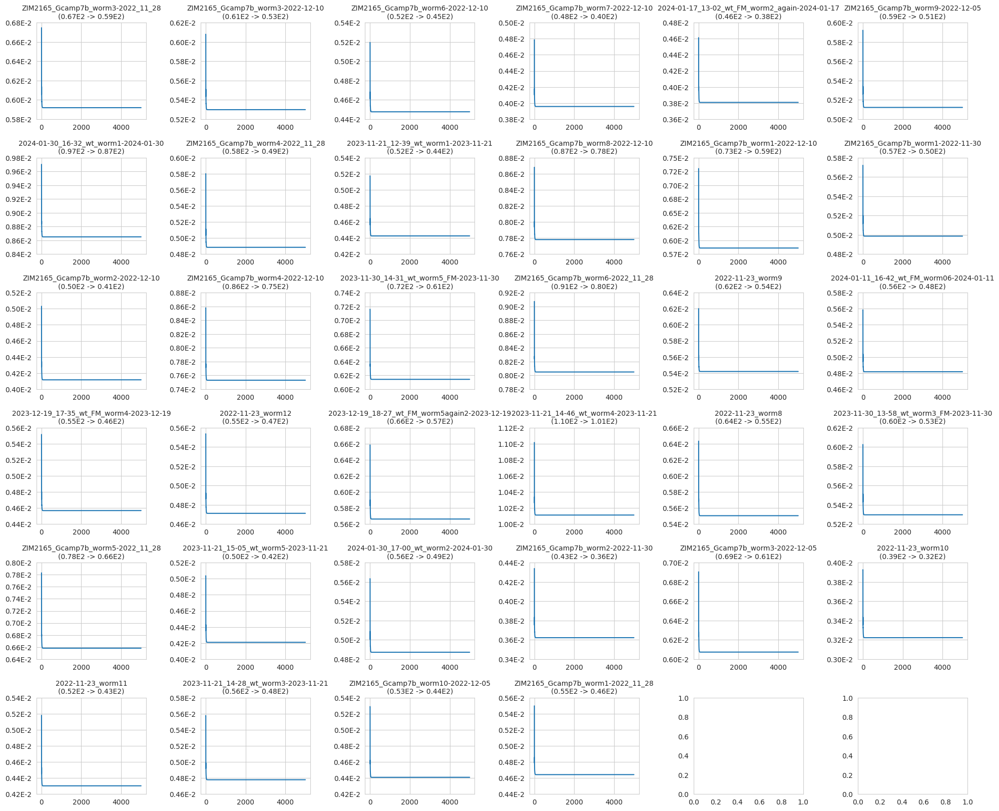

In [23]:
n_plots = 36
dim = math.ceil(math.sqrt(n_plots))
fig, axes = plt.subplots(dim, dim, figsize=(24, 20))
for i in range(n_plots):
	#axes[i // dim, i % dim].set_xticklabels([])
	#axes[i // dim, i % dim].set_yticklabels([])
	axes[i // dim, i % dim].grid(False)

for i, history in enumerate(models_histories_glm):
	axes[i // dim, i % dim].plot(history)
	axes[i // dim, i % dim].grid(True)
	axes[i // dim, i % dim].set_title(f'{filenames[i][:-14]}\n({history[0]*100:.2f}E2 -> {history[-1]*100:.2f}E2)', fontsize=10)

	yticks = axes[i // dim, i % dim].get_yticks()
	axes[i // dim, i % dim].set_yticks(yticks)
	axes[i // dim, i % dim].set_yticklabels([f'{tick * 100:.2f}E-2' for tick in yticks])

fig.subplots_adjust(hspace=0.4, wspace=0.5)

In [24]:
def init_params_hgm(shape_X, shape_X_man):
    return {
        'W1': 1E-2 * jax.random.normal(random_key, shape_X),	# randomly initialize weights
        'W2': 1E-2 * jax.random.normal(random_key, shape_X_man)
    }

def predict_hgm(W_1, W_2, X, X_man):
	return X @ W_1 * jax.nn.sigmoid(X_man @ W_2)	# (n, p) @ (p, k) → (n, k)

def loss_fn_hgm(params, X, X_man, Y):
    Y_pred = predict_hgm(params['W1'], params['W2'], X, X_man)
    return jnp.mean((Y_pred - Y) ** 2)  # MSE

@jax.jit
def update_hgm(opt_state, params, X, X_man, Y):
    loss, grads = jax.value_and_grad(loss_fn_hgm)(params, X, X_man, Y)
    params_updates, opt_state = optimizer.update(grads, opt_state, params)
    params_new = optax.apply_updates(params, params_updates)
    return params_new, loss, opt_state



models_params_hgm = list()
models_histories_hgm = list()
for i in range(len(eigenworms)):
	print(f'{i} ', end='')

	X, X_man, Y = eigenworms[i].values, neuronal_modes[i].values, neuronal_residuals[i].values

	params_hgm = init_params_hgm((X.shape[1], Y.shape[1]), (X_man.shape[1], Y.shape[1]))
	opt_state_hgm = optimizer.init(params_hgm)

	history_hgm = [loss_fn_hgm(params_hgm, X, X_man, Y)]
	for epoch in range(5000):
		params_hgm, loss_hgm, opt_state_hgm = update_hgm(opt_state_hgm, params_hgm, X, X_man, Y)
		history_hgm.append(loss_hgm)

	models_params_hgm.append(params_hgm)
	models_histories_hgm.append(history_hgm)

0 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26 27 28 29 30 31 32 33 

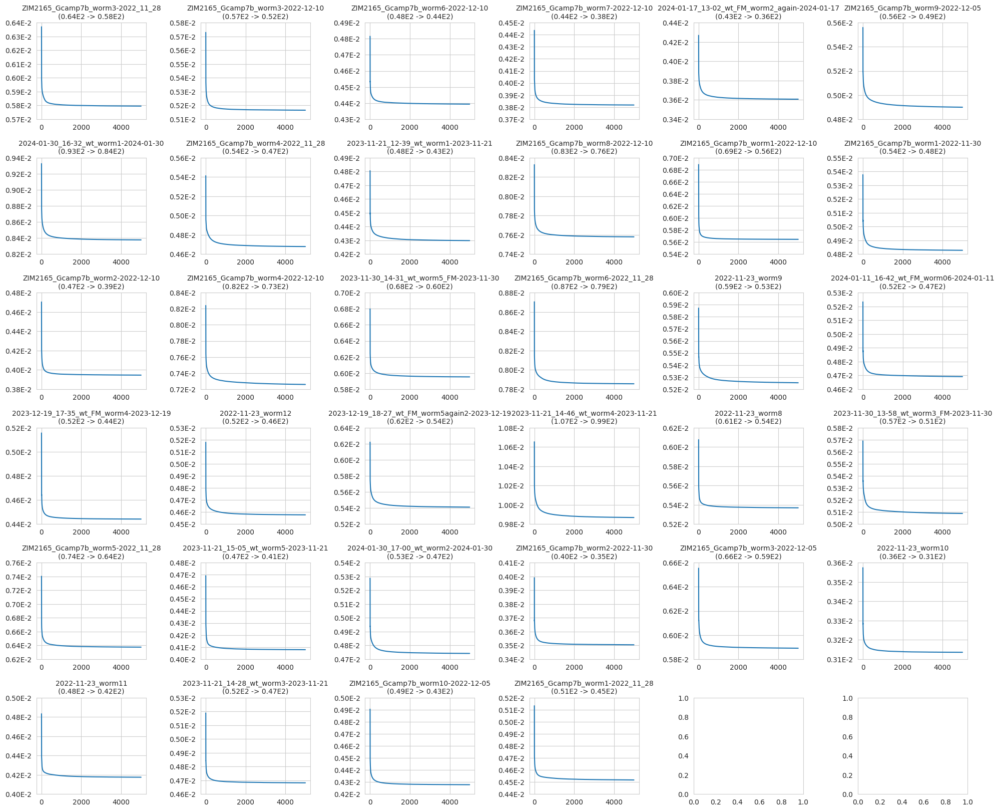

In [25]:
n_plots = 36
dim = math.ceil(math.sqrt(n_plots))
fig, axes = plt.subplots(dim, dim, figsize=(24, 20))
for i in range(n_plots):
	#axes[i // dim, i % dim].set_xticklabels([])
	#axes[i // dim, i % dim].set_yticklabels([])
	axes[i // dim, i % dim].grid(False)

for i, history in enumerate(models_histories_hgm):
	axes[i // dim, i % dim].plot(history)
	axes[i // dim, i % dim].grid(True)
	axes[i // dim, i % dim].set_title(f'{filenames[i][:-14]}\n({history[0]*100:.2f}E2 -> {history[-1]*100:.2f}E2)', fontsize=10)

	yticks = axes[i // dim, i % dim].get_yticks()
	axes[i // dim, i % dim].set_yticks(yticks)
	axes[i // dim, i % dim].set_yticklabels([f"{tick * 100:.2f}E-2" for tick in yticks])

fig.subplots_adjust(hspace=0.4, wspace=0.5)

In [26]:
residuals_pred_glm = list()
residuals_pred_hgm = list()
for i in range(len(eigenworms)):
	ews = eigenworms[i].values
	signal_reduced = neuronal_modes[i].values

	params_glm = models_params_glm[i]
	params_hgm = models_params_hgm[i]

	pred_glm = predict_glm(params_glm['W'], ews)
	pred_hgm = predict_hgm(params_hgm['W1'], params_hgm['W2'], ews, signal_reduced)

	residuals_pred_glm.append(pred_glm)
	residuals_pred_hgm.append(pred_hgm)

In [27]:
scores_glm = list()
scores_hgm = list()
labels = list()
for i in range(len(eigenworms)):
	y_pred_glm = residuals_pred_glm[i]
	y_pred_hgm = residuals_pred_hgm[i]
	y = neuronal_residuals[i].values
	names = neuronal_residuals[i].columns
	score_glm = [r2_score(trace, trace_pred) for trace, trace_pred in zip(y.T, y_pred_glm.T)]
	score_hgm = [r2_score(trace, trace_pred) for trace, trace_pred in zip(y.T, y_pred_hgm.T)]

	scores_glm.append(score_glm)
	scores_hgm.append(score_hgm)
	labels.append(names)

In [29]:
blacklist = ['ANTIcor2R?', 'ANTIcorL', 'ANTIcorR', 'VG_anter_FWD_no_curve_L', 'VG_middle_ramping_L', 'VG_middle_ramping_R', 'VG_post_FWD_L', 'VG_post_FWD_R']
unique_labels = sorted(list(set([l for label in labels for l in label])))
unique_labels_filtered = [label for label in unique_labels if label != '' and label[-1] != '_' and label not in blacklist]

neuron_scores = dict()
for label_list, score_glm_list, score_hgm_list in zip(labels, scores_glm, scores_hgm):
	for i in range(len(label_list)):
		label = label_list[i]
		if label != '' and label[-1] != '_' and label not in blacklist:
			score_glm_new, score_hgm_new = np.array(score_glm_list[i]), np.array(score_hgm_list[i])
			if label not in neuron_scores.keys():
				neuron_scores[label] = (score_glm_new, score_hgm_new)
			else:
				score_glm_prev, score_hgm_prev = neuron_scores[label]
				neuron_scores[label] = (np.vstack([score_glm_prev, score_glm_new]), np.vstack([score_hgm_prev, score_hgm_new]))

# SOME SINGULAR TRACES

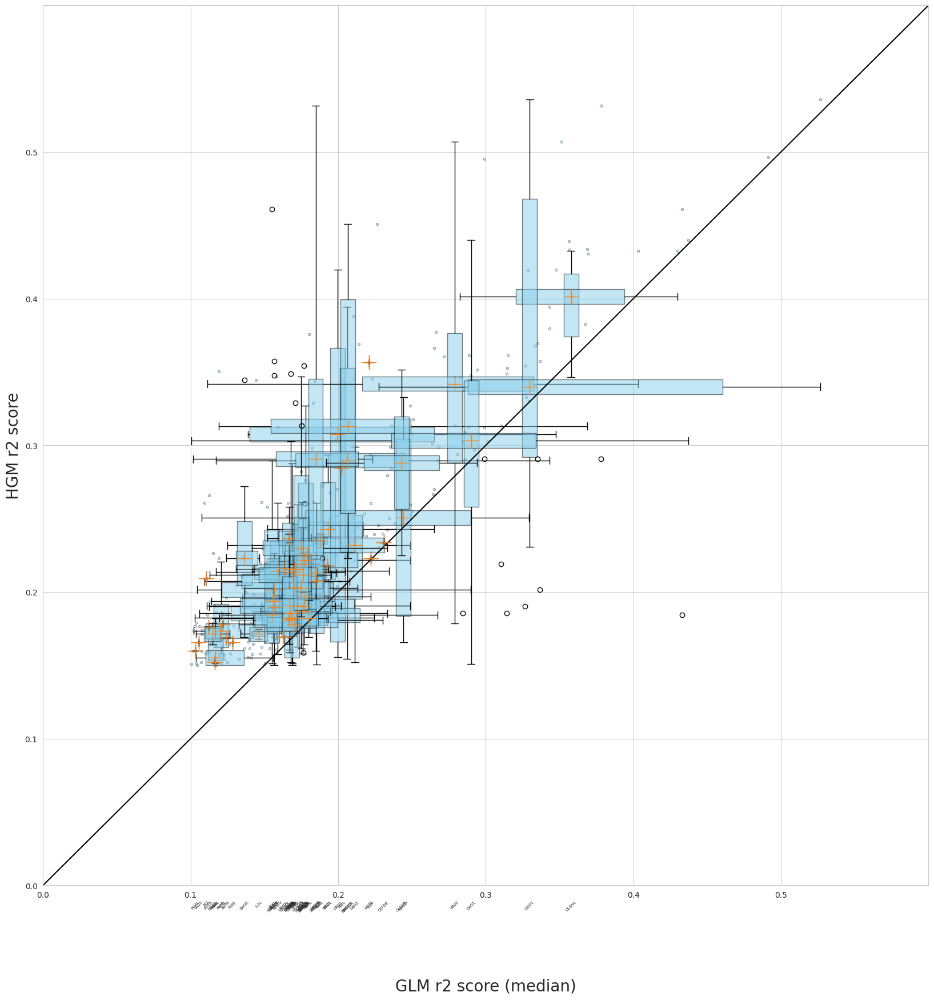

In [61]:
cmap = plt.get_cmap('tab20')
colors = [cmap(i) for i in range(20)]

plt.figure(figsize=(20, 20))
plt.xlabel('GLM r2 score (median)', fontsize=20, labelpad=100)
plt.ylabel('HGM r2 score', fontsize=20)

bp_ticks, bp_tick_labels = list(), list()

keys = neuron_scores.keys()
# keys = ['SMDDR', 'RMDDR']
for key in keys:
	scores_glm, scores_hgm = neuron_scores[key]
	if len(scores_hgm.shape) == 0:
		scores_glm = scores_glm.reshape(1, 1)
		scores_hgm = scores_hgm.reshape(1, 1)
	filters = (scores_glm > 0.1) & (scores_hgm > 0.15)
	scores_glm, scores_hgm = scores_glm[filters], scores_hgm[filters]
	if len(scores_glm) == 0: continue

	x = np.median(scores_glm)
	y = np.median(scores_hgm)
	box_h = plt.boxplot(scores_hgm, positions=[x], widths=0.01, patch_artist=True, showfliers=True)
	box_v = plt.boxplot(scores_glm, positions=[y], widths=0.01, patch_artist=True, showfliers=True, vert=False)
	for box in [box_h, box_v]:
		for patch in box['boxes']:
			patch.set_facecolor('skyblue')
			patch.set_alpha(0.5)

	bp_ticks.append(x)
	bp_tick_labels.append(f'{key}')

	plt.scatter(scores_glm, scores_hgm, s=10, c='skyblue', edgecolor='black', linewidth=0.5, alpha=0.5)

for x, label in zip(bp_ticks, bp_tick_labels):
    plt.text(x, -0.01, label, ha='center', va='top', rotation=45, fontsize=5, transform=plt.gca().transData)

max_x = 0.6
max_y = 0.6
plt.xlim(0, max_x)
plt.ylim(0, max_y)
plt.xticks(np.arange(0, max_x, 0.1), [f'{val:.1f}' for val in np.arange(0, max_x, 0.1)])
plt.yticks(np.arange(0, max_y, 0.1), [f'{val:.1f}' for val in np.arange(0, max_y, 0.1)])

step = 0.01
plt.plot(np.arange(0, max_y + step, step), np.arange(0, max_x + step, step), color='black')

plt.savefig('out/hgm-vs-glm-scores', dpi=300)

In [32]:
residuals_pred_glm_df = pd.DataFrame(residuals_pred_glm, columns=neuronal_traces.columns)
heatmap = discrete_states['FWD'].values.reshape(-1, 1) * 0.1

dim1, dim2 = 20, 2
fig, axes = plt.subplots(dim1, dim2, figsize=(20, 45), constrained_layout=True)
for i in range(dim1 * dim2):
	#axes[i // dim2, i % dim2].set_xticklabels([])
	#axes[i // dim2, i % dim2].set_yticklabels([])
	axes[i // dim2, i % dim2].grid(False)

i = 0
for key in residuals_pred_glm_df:
	if key != '':
		min_val, max_val = min(residuals_pred_glm_df[key]), max(residuals_pred_glm_df[key])
		axes[i // dim2, i % dim2].imshow(
			heatmap.T, aspect='auto', cmap='rainbow', interpolation='nearest', alpha=0.3, extent=[0, heatmap.shape[0], min_val, max_val]
		)
		axes[i // dim2, i % dim2].plot(residuals_pred_glm_df[key], color='black', linewidth=1.0)
		axes[i // dim2, i % dim2].grid(False)
		axes[i // dim2, i % dim2].set_title(f'{key}', fontsize=12)
		i += 1

fig.text(0.5, 1.03, 'Predicted Signals (GLM)', ha='center', fontsize=20)
fig.legend(
    handles=[patches.Patch(color=plt.get_cmap('rainbow')(0.0), alpha=0.3, label='reversal')],
    loc='upper center',
    bbox_to_anchor=(0.5, 1.02),
    ncol=1,
    fontsize='large'
)

AttributeError: 'list' object has no attribute 'columns'

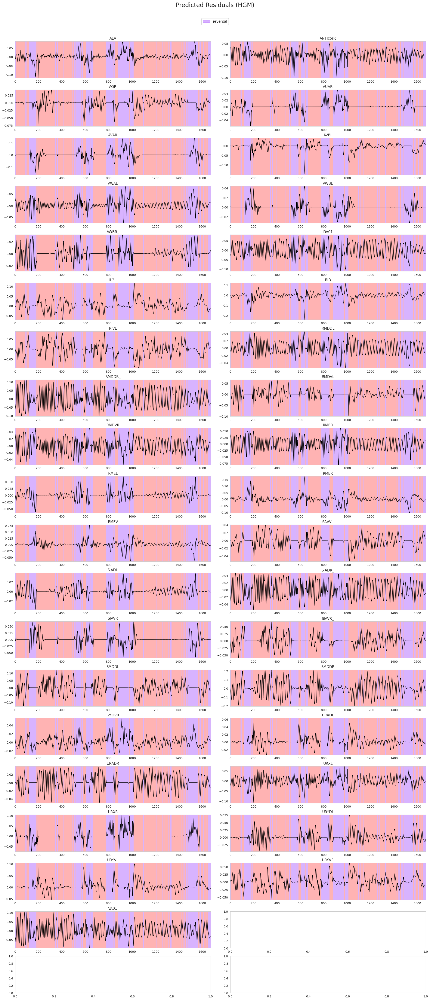

In [16]:
residuals_pred_hgm_df = pd.DataFrame(residuals_pred_hgm, columns=neuronal_traces.columns)
heatmap = discrete_states['FWD'].values.reshape(-1, 1) * 0.1

dim1, dim2 = 20, 2
fig, axes = plt.subplots(dim1, dim2, figsize=(20, 45), constrained_layout=True)
for i in range(dim1 * dim2):
	#axes[i // dim2, i % dim2].set_xticklabels([])
	#axes[i // dim2, i % dim2].set_yticklabels([])
	axes[i // dim2, i % dim2].grid(False)

i = 0
for key in residuals_pred_hgm_df:
	if key != '':
		min_val, max_val = min(residuals_pred_hgm_df[key]), max(residuals_pred_hgm_df[key])
		axes[i // dim2, i % dim2].imshow(
			heatmap.T, aspect='auto', cmap='rainbow', interpolation='nearest', alpha=0.3, extent=[0, heatmap.shape[0], min_val, max_val]
		)
		axes[i // dim2, i % dim2].plot(residuals_pred_hgm_df[key], color='black', linewidth=1.0)
		axes[i // dim2, i % dim2].grid(False)
		axes[i // dim2, i % dim2].set_title(f'{key}', fontsize=12)
		i += 1

fig.text(0.5, 1.03, 'Predicted Residuals (HGM)', ha='center', fontsize=20)
fig.legend(
    handles=[patches.Patch(color=plt.get_cmap('rainbow')(0.0), alpha=0.3, label='reversal')],
    loc='upper center',
    bbox_to_anchor=(0.5, 1.02),
    ncol=1,
    fontsize='large'
)

plt.savefig('out/traces_single_residuals_predicted.png', dpi=300)

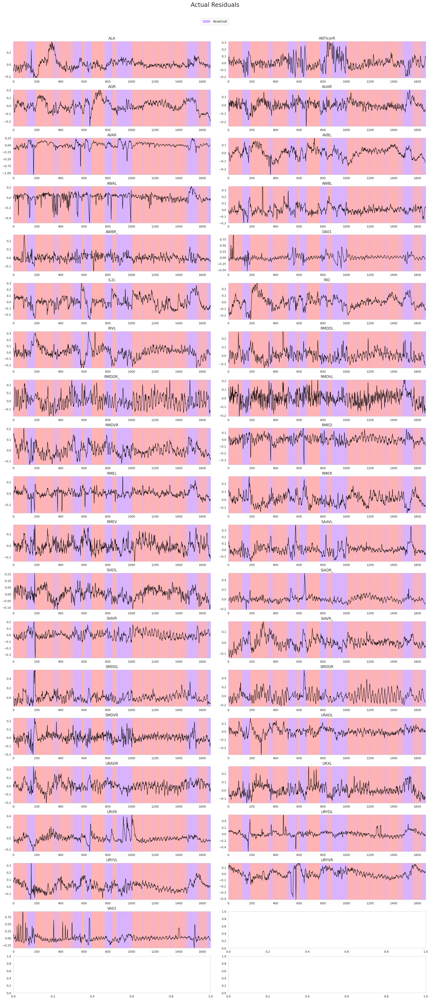

In [17]:
signal_residual_df = pd.DataFrame(data=signal_residual, columns=neuronal_traces.columns)

dim1, dim2 = 20, 2
fig, axes = plt.subplots(dim1, dim2, figsize=(20, 45), constrained_layout=True)
for i in range(dim1 * dim2):
	#axes[i // dim2, i % dim2].set_xticklabels([])
	#axes[i // dim2, i % dim2].set_yticklabels([])
	axes[i // dim2, i % dim2].grid(False)

i = 0
for key in signal_residual_df:
	if key != '':
		min_val, max_val = min(signal_residual_df[key]), max(signal_residual_df[key])
		axes[i // dim2, i % dim2].imshow(
			heatmap.T, aspect='auto', cmap='rainbow', interpolation='nearest', alpha=0.3, extent=[0, heatmap.shape[0], min_val, max_val]
		)
		axes[i // dim2, i % dim2].plot(signal_residual_df[key], color='black', linewidth=1.0)
		axes[i // dim2, i % dim2].grid(False)
		axes[i // dim2, i % dim2].set_title(f'{key}', fontsize=12)
		i += 1

fig.text(0.5, 1.03, 'Actual Residuals', ha='center', fontsize=20)
fig.legend(
    handles=[patches.Patch(color=plt.get_cmap('rainbow')(0.0), alpha=0.3, label='reversal')],
    loc='upper center',
    bbox_to_anchor=(0.5, 1.02),
    ncol=1,
    fontsize='large'
)

plt.savefig('out/traces_single_residuals.png', dpi=300)

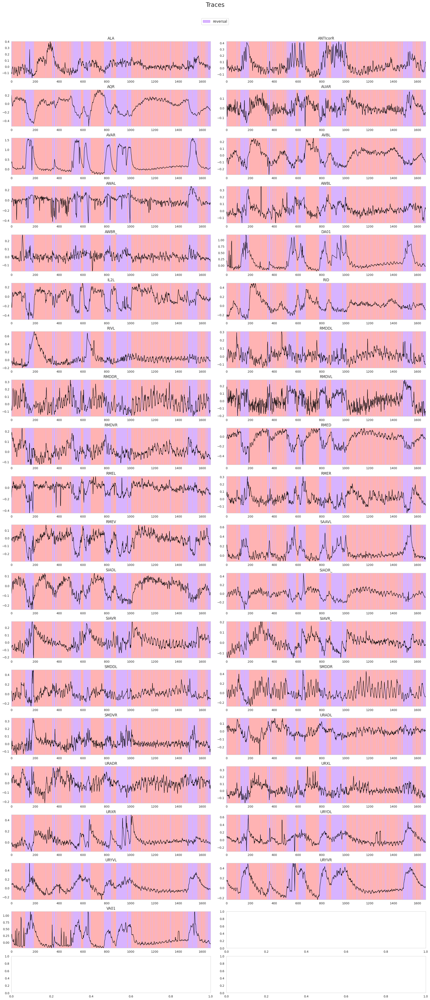

In [18]:
dim1, dim2 = 20, 2
fig, axes = plt.subplots(dim1, dim2, figsize=(20, 45), constrained_layout=True)
for i in range(dim1 * dim2):
	#axes[i // dim2, i % dim2].set_xticklabels([])
	#axes[i // dim2, i % dim2].set_yticklabels([])
	axes[i // dim2, i % dim2].grid(False)

i = 0
for key in neuronal_traces:
	if key != '':
		min_val, max_val = min(neuronal_traces[key]), max(neuronal_traces[key])
		axes[i // dim2, i % dim2].imshow(
			heatmap.T, aspect='auto', cmap='rainbow', interpolation='nearest', alpha=0.3, extent=[0, heatmap.shape[0], min_val, max_val]
		)
		axes[i // dim2, i % dim2].plot(neuronal_traces[key], color='black', linewidth=1.0)
		axes[i // dim2, i % dim2].grid(False)
		axes[i // dim2, i % dim2].set_title(f'{key}', fontsize=12)
		i += 1

fig.text(0.5, 1.03, 'Traces', ha='center', fontsize=20)
fig.legend(
    handles=[patches.Patch(color=plt.get_cmap('rainbow')(0.0), alpha=0.3, label='reversal')],
    loc='upper center',
    bbox_to_anchor=(0.5, 1.02),
    ncol=1,
    fontsize='large'
)

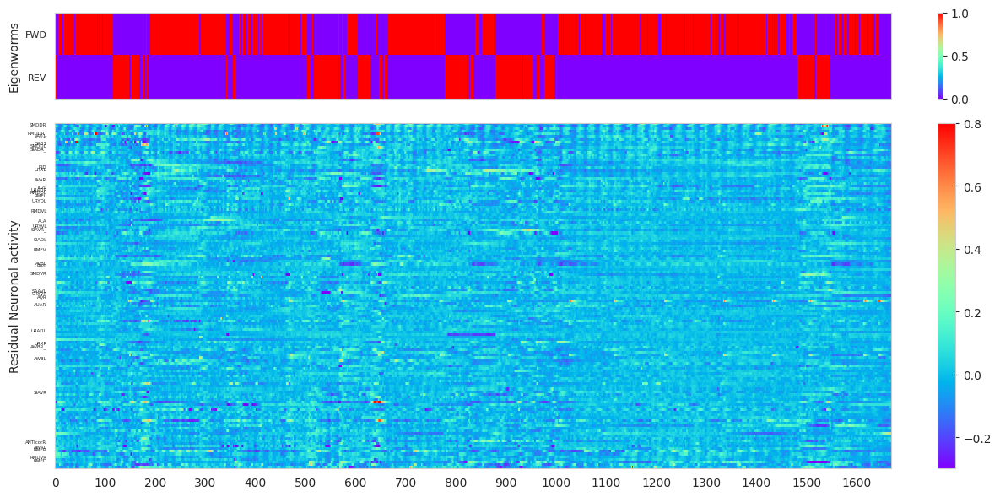

In [7]:
selection = ['FWD', 'REV']

ews = eigenworms.values
ds = discrete_states[selection].values
signal = neuronal_traces.values




cca_residual = CCA(n_components=5, scale=False)  # cca = CCA(n_components=5)
signal_residual_reduced, ews_reduced = cca_residual.fit_transform(signal_residual, ews)
signal_residual_reconstructed, ews_reconstructed = cca_residual.inverse_transform(signal_residual_reduced, ews_reduced)

signal_residual_indices = np.argsort(cca_residual.x_loadings_[:, 0])






fig, (ax_top, ax_3tom) = plt.subplots(2, 1, figsize=(12, 6), sharex=True, gridspec_kw={'height_ratios': [1, 4]})

im_top = ax_top.imshow(ds.T, aspect='auto', cmap='rainbow', interpolation='nearest')
ax_top.set_ylabel("Eigenworms")
ax_top.set_yticks(np.arange(len(ds.T)))
ax_top.set_yticklabels(discrete_states[selection].columns, fontsize=8)
ax_top.set_xticks(np.arange(0, len(ds), 100))
fig.colorbar(im_top, ax=ax_top, orientation='vertical', fraction=0.05)
ax_top.grid(False)

im_bottom = ax_3tom.imshow(np.clip(signal_residual.T[signal_residual_indices], -0.3, 0.8), aspect='auto', cmap='rainbow', interpolation='nearest')
ax_3tom.set_ylabel("Residual Neuronal activity")
ax_3tom.set_yticks(np.arange(len(signal_residual.T)))
ax_3tom.set_yticklabels(neuronal_traces.columns[signal_residual_indices], fontsize=4)
ax_3tom.set_xticks(np.arange(0, len(signal_residual), 100))
fig.colorbar(im_bottom, ax=ax_3tom, orientation='vertical', fraction=0.05)
ax_3tom.grid(False)

plt.tight_layout()
plt.show()

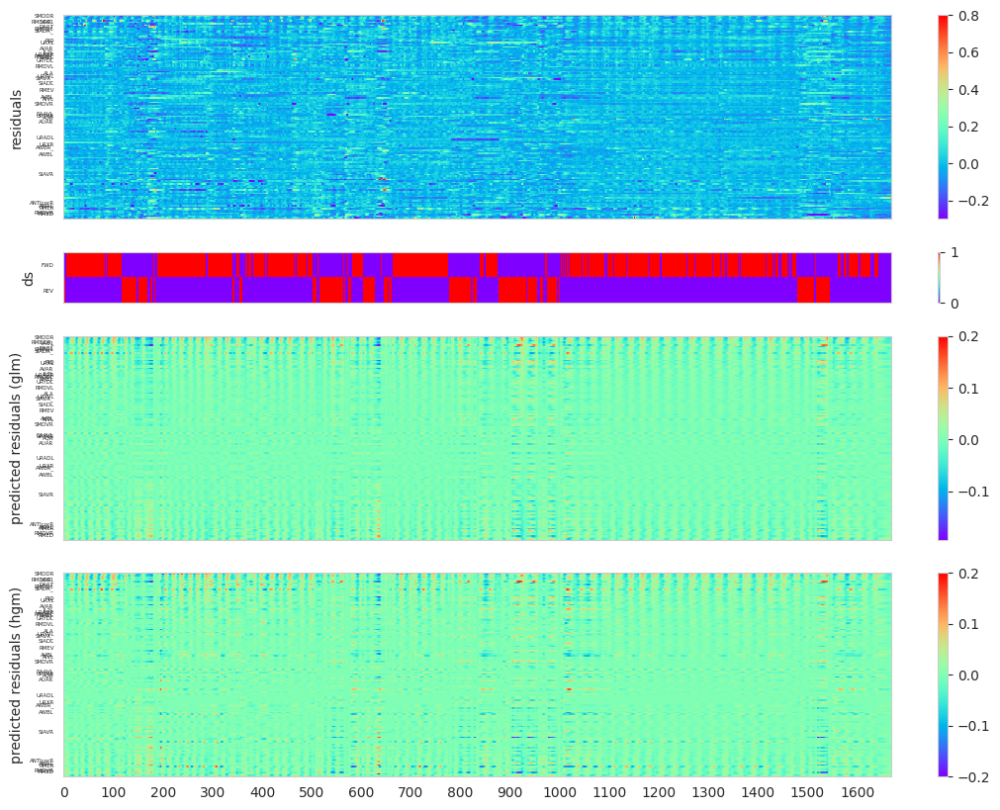

In [12]:


fig, (ax_1, ax_2, ax_3, ax_4) = plt.subplots(4, 1, figsize=(12, 10), sharex=True, gridspec_kw={'height_ratios': [4, 1, 4, 4]})

im_1 = ax_1.imshow(np.clip(signal_residual.T[signal_residual_indices], -0.3, 0.8), aspect='auto', cmap='rainbow', interpolation='nearest')
ax_1.set_ylabel("residuals")
ax_1.set_yticks(np.arange(len(signal_residual.T)))
ax_1.set_yticklabels(neuronal_traces.columns[signal_residual_indices], fontsize=4)
ax_1.set_xticks(np.arange(0, len(signal_residual), 100))
fig.colorbar(im_1, ax=ax_1, orientation='vertical', fraction=0.05)
ax_1.grid(False)

im_2 = ax_2.imshow(ds.T, aspect='auto', cmap='rainbow', interpolation='nearest')
ax_2.set_ylabel("ds")
ax_2.set_yticks(np.arange(len(ds.T)))
ax_2.set_yticklabels(discrete_states[selection].columns, fontsize=4)
ax_2.set_xticks(np.arange(0, len(ds), 100))
fig.colorbar(im_2, ax=ax_2, orientation='vertical', fraction=0.05)
ax_2.grid(False)

im_3 = ax_3.imshow(np.clip(residuals_pred_glm.T[signal_residual_indices], -0.2, 0.2), aspect='auto', cmap='rainbow', interpolation='nearest')
ax_3.set_ylabel("predicted residuals (glm)")
ax_3.set_yticks(np.arange(len(residuals_pred_glm.T)))
ax_3.set_yticklabels(neuronal_traces.columns[signal_residual_indices], fontsize=4)
ax_3.set_xticks(np.arange(0, len(residuals_pred_glm), 100))
fig.colorbar(im_3, ax=ax_3, orientation='vertical', fraction=0.05)
ax_3.grid(False)

im_4 = ax_4.imshow(np.clip(residuals_pred_hgm.T[signal_residual_indices], -0.2, 0.2), aspect='auto', cmap='rainbow', interpolation='nearest')
ax_4.set_ylabel("predicted residuals (hgm)")
ax_4.set_yticks(np.arange(len(residuals_pred_hgm.T)))
ax_4.set_yticklabels(neuronal_traces.columns[signal_residual_indices], fontsize=4)
ax_4.set_xticks(np.arange(0, len(residuals_pred_hgm), 100))
fig.colorbar(im_4, ax=ax_4, orientation='vertical', fraction=0.05)
ax_4.grid(False)

plt.savefig('out/traces_residuals_predicted.png', dpi=300)